# Notebook 4: Model Comparison and Analysis

<div dir="rtl" align="right">

يقارن هذا الملف بين نموذجي Logistic Regression و Random Forest على نفس بيانات الاختبار. يقرأ النتائج المحفوظة من Notebook 2 و Notebook 3، ثم يعرض جدول المقارنة والرسوم وتحليل الأخطاء وتفسير النموذجين.

</div>

## 1. Import Libraries

<div dir="rtl" align="right">

تستورد الخلية التالية المكتبات المطلوبة لقراءة النتائج ورسم المقارنات.

</div>

In [1]:
# os is used to create folders
import os
# pandas is used to read and handle data tables
import pandas as pd
# matplotlib is used to draw charts
import matplotlib.pyplot as plt
# tools for the confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# tools for the precision-recall and ROC curves
from sklearn.metrics import precision_recall_curve, roc_curve

## 2. Set Paths

<div dir="rtl" align="right">

تحدد الخلية التالية مجلد النتائج ومجلد البيانات المقسّمة.

</div>

<div dir="rtl" align="right">

تربط الخلية التالية Google Drive مع Colab وتحدد مجلد المشروع `churn_project` في My Drive. جميع المسارات بعد ذلك مبنية على هذا المجلد، لذلك تُحفظ كل النتائج في Drive.

</div>

In [2]:
# tool that connects Google Drive to Colab
from google.colab import drive
# connect Google Drive (Colab asks for permission the first time)
drive.mount("/content/drive")
# project folder inside Google Drive
BASE_FOLDER = "/content/drive/MyDrive/churn_project"
# print the project folder that will be used
print("Project folder:", BASE_FOLDER)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/churn_project


In [3]:
# folder that contains the saved results of both models
RESULTS_FOLDER = BASE_FOLDER + "/results"
# folder that contains the split files from Notebook 1
SPLIT_FOLDER = BASE_FOLDER + "/data/splits"
# create the results folder if it does not exist
os.makedirs(RESULTS_FOLDER, exist_ok=True)

## 3. Load the Metrics of Both Models

<div dir="rtl" align="right">

تقرأ الخلية التالية ملف المقاييس لكل نموذج وتجمعهما في جدول واحد للمقارنة.

</div>

In [4]:
# Read the Logistic Regression metrics
lr_metrics = pd.read_csv(RESULTS_FOLDER + "/logistic_regression_metrics.csv")
# Read the Random Forest metrics
rf_metrics = pd.read_csv(RESULTS_FOLDER + "/rf_metrics.csv")

# Rename the Logistic Regression F1 column so it matches the Random Forest format
lr_metrics = lr_metrics.rename(columns={"f1_score": "f1"})

# The Logistic Regression metrics file does not contain TN/FP/FN/TP,
# so we calculate them from its saved test predictions
lr_test_pred = pd.read_csv(RESULTS_FOLDER + "/logistic_regression_predictions.csv")
tn_lr, fp_lr, fn_lr, tp_lr = confusion_matrix(
    lr_test_pred["actual_churn"], lr_test_pred["predicted_churn"]
).ravel()
lr_metrics["TN"] = tn_lr
lr_metrics["FP"] = fp_lr
lr_metrics["FN"] = fn_lr
lr_metrics["TP"] = tp_lr

# C and class_weight belong only to Logistic Regression (the text "None" is also read
# as a missing value by pandas), so they are removed from the shared comparison table
lr_metrics = lr_metrics.drop(columns=["C", "class_weight"], errors="ignore")

# Join both model metrics into one comparison table
comparison = pd.concat([lr_metrics, rf_metrics], ignore_index=True)

# Make sure the confusion-matrix counts are whole numbers
comparison[["TN", "FP", "FN", "TP"]] = comparison[["TN", "FP", "FN", "TP"]].astype(int)

# Save the comparison table
comparison.to_csv(RESULTS_FOLDER + "/model_comparison.csv", index=False)

# Display the comparison table
display(comparison.round(4))

,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,TN,FP,FN,TP
0,Logistic Regression,0.35,0.8822,0.6000,0.6087,0.6043,0.7171,0.9284,370,28,27,42
1,Random Forest,0.55,0.9315,0.9302,0.5797,0.7143,0.9147,0.9796,395,3,29,40


## 4. Compare the Metrics in a Chart

<div dir="rtl" align="right">

ترسم الخلية التالية المقاييس الستة للنموذجين جنباً إلى جنب لتسهيل المقارنة.

</div>

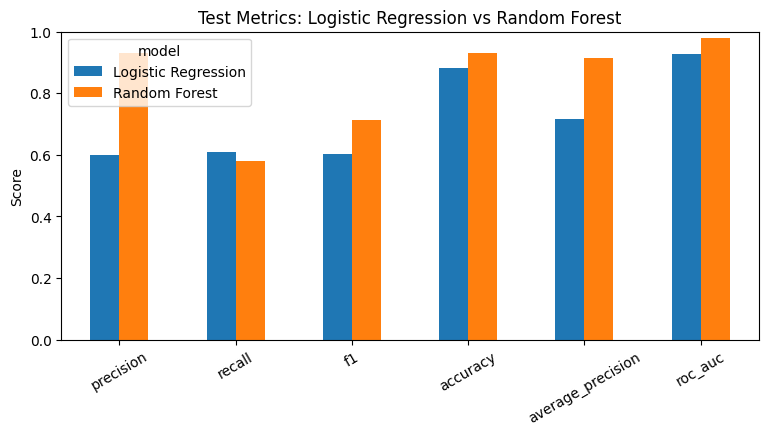

In [5]:
# names of the metrics to draw
metric_names = ["precision", "recall", "f1", "accuracy", "average_precision", "roc_auc"]
# keep the metric columns and use the model name as the row label
chart_data = comparison.set_index("model")[metric_names]
# draw a grouped bar chart (one group for each metric)
chart_data.T.plot(kind="bar", figsize=(9, 4))
# set the chart title
plt.title("Test Metrics: Logistic Regression vs Random Forest")
# set the y-axis label
plt.ylabel("Score")
# set the y-axis range from 0 to 1
plt.ylim(0, 1)
# rotate the metric names to make them readable
plt.xticks(rotation=30)
# save the chart as an image
plt.savefig(RESULTS_FOLDER + "/comparison_metrics.png", dpi=150, bbox_inches="tight")
# display the chart
plt.show()

## 5. Load the Test Predictions

<div dir="rtl" align="right">

تقرأ الخلية التالية توقعات النموذجين على بيانات الاختبار وتدمجها حسب رقم الصف، ثم تتأكد أن النموذجين تم تقييمهما على نفس العملاء ونفس القيم الحقيقية.

</div>

In [6]:
# Read the Logistic Regression test predictions
lr_pred = pd.read_csv(
    RESULTS_FOLDER + "/logistic_regression_predictions.csv"
)

# Rename the Logistic Regression columns
# so they match the format used by Notebook 4
lr_pred = lr_pred.rename(columns={
    "actual_churn": "y_true",
    "predicted_churn": "prediction",
    "churn_probability": "probability"
})

# Read the Random Forest test predictions
rf_pred = pd.read_csv(
    RESULTS_FOLDER + "/rf_test_predictions.csv"
)

# Join the two prediction tables using row_id
both = lr_pred.merge(
    rf_pred,
    on="row_id",
    suffixes=("_lr", "_rf")
)

# Show the number of rows in each table
print(
    "LR rows:", len(lr_pred),
    "| RF rows:", len(rf_pred),
    "| Matched rows:", len(both)
)

# Check that both models used the same true labels
print(
    "Same true labels:",
    (both["y_true_lr"] == both["y_true_rf"]).all()
)

# Keep one common true-label column
both["y_true"] = both["y_true_lr"]

LR rows: 467 | RF rows: 467 | Matched rows: 467
Same true labels: True


## 6. Confusion Matrices Side by Side

<div dir="rtl" align="right">

ترسم الخلية التالية مصفوفة الالتباس لكل نموذج في شكل واحد لمقارنة عدد المغادرين المكتشفين والتنبيهات الخاطئة.

</div>

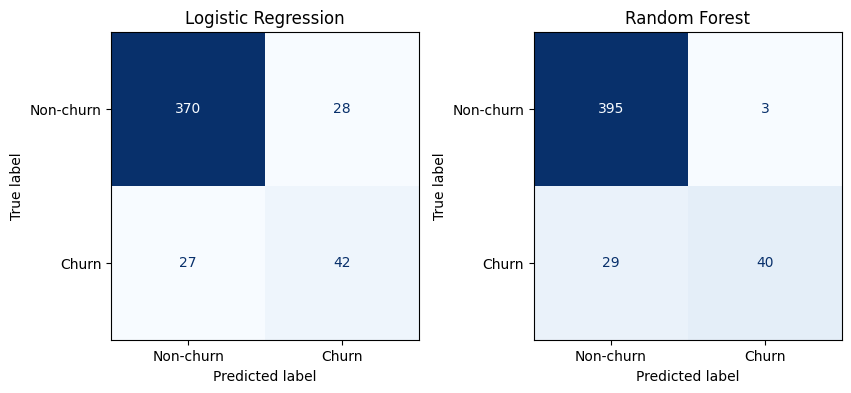

In [7]:
# create one figure with two charts
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# calculate the confusion matrix of Logistic Regression
cm_lr = confusion_matrix(both["y_true"], both["prediction_lr"])
# calculate the confusion matrix of Random Forest
cm_rf = confusion_matrix(both["y_true"], both["prediction_rf"])
# draw the Logistic Regression matrix in the first chart
ConfusionMatrixDisplay(cm_lr, display_labels=["Non-churn", "Churn"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
# set the title of the first chart
axes[0].set_title("Logistic Regression")
# draw the Random Forest matrix in the second chart
ConfusionMatrixDisplay(cm_rf, display_labels=["Non-churn", "Churn"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
# set the title of the second chart
axes[1].set_title("Random Forest")
# save the figure as an image
plt.savefig(RESULTS_FOLDER + "/comparison_confusion_matrices.png", dpi=150, bbox_inches="tight")
# display the figure
plt.show()

## 7. Precision-Recall and ROC Curves

<div dir="rtl" align="right">

ترسم الخلية التالية منحنى Precision-Recall ومنحنى ROC للنموذجين. توضح هذه المنحنيات أداء كل نموذج عند جميع حدود التصنيف وليس عند الحد المختار فقط.

</div>

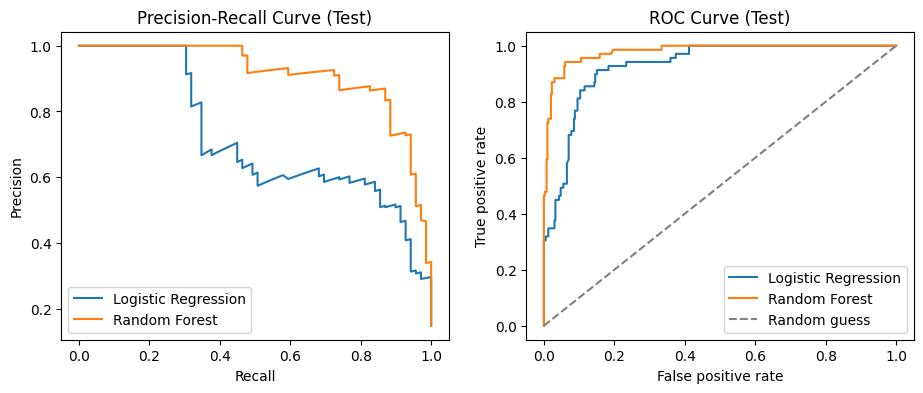

In [8]:
# create one figure with two charts
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# calculate the precision-recall curve of Logistic Regression
p_lr, r_lr, _ = precision_recall_curve(both["y_true"], both["probability_lr"])
# calculate the precision-recall curve of Random Forest
p_rf, r_rf, _ = precision_recall_curve(both["y_true"], both["probability_rf"])
# draw the Logistic Regression precision-recall curve
axes[0].plot(r_lr, p_lr, label="Logistic Regression")
# draw the Random Forest precision-recall curve
axes[0].plot(r_rf, p_rf, label="Random Forest")
# set the title of the first chart
axes[0].set_title("Precision-Recall Curve (Test)")
# set the x-axis label of the first chart
axes[0].set_xlabel("Recall")
# set the y-axis label of the first chart
axes[0].set_ylabel("Precision")
# show the legend of the first chart
axes[0].legend()
# calculate the ROC curve of Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(both["y_true"], both["probability_lr"])
# calculate the ROC curve of Random Forest
fpr_rf, tpr_rf, _ = roc_curve(both["y_true"], both["probability_rf"])
# draw the Logistic Regression ROC curve
axes[1].plot(fpr_lr, tpr_lr, label="Logistic Regression")
# draw the Random Forest ROC curve
axes[1].plot(fpr_rf, tpr_rf, label="Random Forest")
# draw the diagonal line of a random model
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guess")
# set the title of the second chart
axes[1].set_title("ROC Curve (Test)")
# set the x-axis label of the second chart
axes[1].set_xlabel("False positive rate")
# set the y-axis label of the second chart
axes[1].set_ylabel("True positive rate")
# show the legend of the second chart
axes[1].legend()
# save the figure as an image
plt.savefig(RESULTS_FOLDER + "/comparison_curves.png", dpi=150, bbox_inches="tight")
# display the figure
plt.show()

## 8. Error Analysis: False Negatives and False Positives

<div dir="rtl" align="right">

تعرض الخلية التالية نوعي الخطأ لكل نموذج: False Negatives وهم المغادرون الذين لم يكتشفهم النموذج، و False Positives وهم العملاء الباقون الذين صنفهم النموذج كمغادرين.

</div>

In [9]:
# number of real churners in the test data
total_churners = comparison["FN"] + comparison["TP"]
# number of real non-churners in the test data
total_non_churners = comparison["TN"] + comparison["FP"]
# build a table with the two error types of each model
error_table = pd.DataFrame({
    "model": comparison["model"],
    "false_negatives": comparison["FN"],
    "missed_churners_%": (comparison["FN"] / total_churners * 100).round(2),
    "false_positives": comparison["FP"],
    "false_alarms_%": (comparison["FP"] / total_non_churners * 100).round(2),
})
# save the error table
error_table.to_csv(RESULTS_FOLDER + "/error_analysis.csv", index=False)
# show the error table
error_table

,model,false_negatives,missed_churners_%,false_positives,false_alarms_%
0,Logistic Regression,27,39.13,28,7.04
1,Random Forest,29,42.03,3,0.75


## 9. Error Analysis: Agreement Between the Models

<div dir="rtl" align="right">

تفحص الخلية التالية المغادرين الحقيقيين في بيانات الاختبار، وتعدّ من اكتشفه النموذجان معاً، ومن اكتشفه نموذج واحد فقط، ومن لم يكتشفه أي منهما.

</div>

In [10]:
# keep only the customers who really churned
churners = both[both["y_true"] == 1]
# count churners detected by both models
detected_by_both = ((churners["prediction_lr"] == 1) & (churners["prediction_rf"] == 1)).sum()
# count churners detected by Logistic Regression only
detected_by_lr_only = ((churners["prediction_lr"] == 1) & (churners["prediction_rf"] == 0)).sum()
# count churners detected by Random Forest only
detected_by_rf_only = ((churners["prediction_lr"] == 0) & (churners["prediction_rf"] == 1)).sum()
# count churners missed by both models
missed_by_both = ((churners["prediction_lr"] == 0) & (churners["prediction_rf"] == 0)).sum()
# print the total number of real churners
print("Real churners in the test set:", len(churners))
# print the number detected by both models
print("Detected by both models:", detected_by_both)
# print the number detected by Logistic Regression only
print("Detected by Logistic Regression only:", detected_by_lr_only)
# print the number detected by Random Forest only
print("Detected by Random Forest only:", detected_by_rf_only)
# print the number missed by both models
print("Missed by both models:", missed_by_both)

Real churners in the test set: 69
Detected by both models: 35
Detected by Logistic Regression only: 7
Detected by Random Forest only: 5
Missed by both models: 22


## 10. Error Analysis: Profile of the Missed Churners

<div dir="rtl" align="right">

تقارن الخلية التالية متوسط الخصائص بين المغادرين الذين اكتشفهم كل نموذج والمغادرين الذين لم يكتشفهم، وذلك لـ Logistic Regression و Random Forest، لمعرفة نوع العملاء الذين يصعب على كل نموذج اكتشافهم.

</div>

In [11]:
# read the test data to get the feature values
test = pd.read_csv(SPLIT_FOLDER + "/test.csv")
# add the feature values to the predictions table
test_with_pred = both.merge(test, on="row_id")
# keep only the customers who really churned
test_churners = test_with_pred[test_with_pred["y_true"] == 1]
# features to compare
profile_features = ["Call Failure", "Subscription Length", "Seconds of Use", "Frequency of use", "Frequency of SMS", "Distinct Called Numbers", "Complains"]

# repeat the same comparison for both models
for model_name, pred_column, file_name in [
    ("Logistic Regression", "prediction_lr", "lr_missed_churners_profile.csv"),
    ("Random Forest", "prediction_rf", "rf_missed_churners_profile.csv"),
]:
    # mean of each feature for missed (0) and detected (1) churners
    profile_table = test_churners.groupby(pred_column)[profile_features].mean().round(2)
    # count how many churners are in each group
    group_sizes = test_churners[pred_column].value_counts()
    # rename the rows to clear names (with the group size)
    profile_table.index = [
        ("missed" if p == 0 else "detected") + f" (n={group_sizes[p]})"
        for p in profile_table.index
    ]
    # save the profile table
    profile_table.to_csv(RESULTS_FOLDER + "/" + file_name)
    # show the table with features as rows
    print(model_name)
    display(profile_table.T)

Logistic Regression


,missed (n=27),detected (n=42)
Call Failure,5.07,10.38
Subscription Length,31.48,32.60
Seconds of Use,2187.48,1859.10
Frequency of use,35.89,35.31
Frequency of SMS,14.30,14.71
Distinct Called Numbers,14.85,14.40
Complains,0.00,0.55


Random Forest


,missed (n=29),detected (n=40)
Call Failure,5.17,10.58
Subscription Length,31.38,32.72
Seconds of Use,1906.69,2046.25
Frequency of use,33.03,37.35
Frequency of SMS,10.93,17.18
Distinct Called Numbers,12.79,15.88
Complains,0.00,0.57


## 11. Model Interpretation

<div dir="rtl" align="right">

تعرض الخلية التالية تفسير النموذجين: معاملات Logistic Regression (الإشارة الموجبة تعني ارتباطاً بزيادة احتمال المغادرة والسالبة بانخفاضه)، وأهمية الخصائص في Random Forest. هذه النتائج تدل على ارتباط تنبؤي وليست دليلاً على علاقة سببية.

</div>
<div dir="rtl" align="right">

**ملاحظة مهمة:** متغيرات Charge Amount و Tariff Plan و Status مشفّرة بـ one-hot دون حذف فئة مرجعية، فالفئات مترابطة تماماً. لذلك لا تُفسَّر إشارة معامل فئة واحدة بمفردها (مثلاً Status_1 و Status_2 كلاهما سالب)، بل يُنظر إلى الفرق بين معاملات فئات نفس المتغير.

</div>

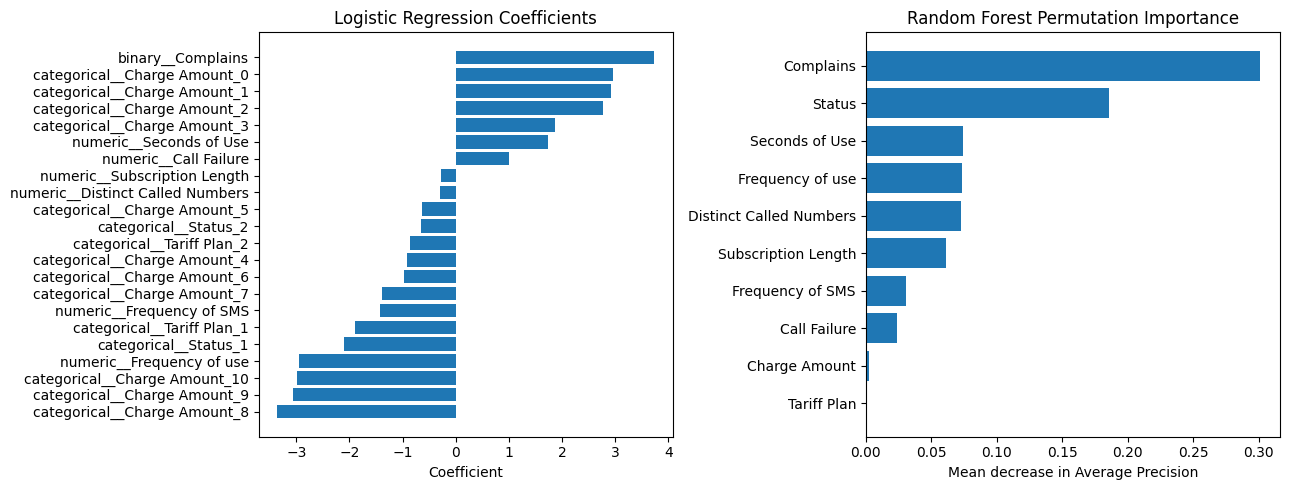

In [12]:
# read the Logistic Regression coefficients

lr_coef = pd.read_csv(
    RESULTS_FOLDER + "/logistic_regression_coefficients.csv"
)
# read the Random Forest feature importance
rf_importance = pd.read_csv(RESULTS_FOLDER + "/rf_feature_importance.csv")
# sort the coefficients from lowest to highest
lr_coef = lr_coef.sort_values("coefficient")
# sort the importance values from lowest to highest
rf_importance = rf_importance.sort_values("importance")
# create one figure with two charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# draw the coefficients as horizontal bars
axes[0].barh(lr_coef["feature"], lr_coef["coefficient"])
# set the title of the first chart
axes[0].set_title("Logistic Regression Coefficients")
# set the x-axis label of the first chart
axes[0].set_xlabel("Coefficient")
# draw the importance values as horizontal bars
axes[1].barh(rf_importance["feature"], rf_importance["importance"])
# set the title of the second chart
axes[1].set_title("Random Forest Permutation Importance")
# set the x-axis label of the second chart
axes[1].set_xlabel("Mean decrease in Average Precision")
# add space between the two charts
plt.tight_layout()
# save the figure as an image
plt.savefig(RESULTS_FOLDER + "/comparison_interpretation.png", dpi=150, bbox_inches="tight")
# display the figure
plt.show()

## 12. Uncertainty of the Test Results (Bootstrap)

<div dir="rtl" align="right">

يحتوي ملف الاختبار على 69 مغادراً فقط، لذلك كل عميل يغيّر الـ recall بحوالي 1.4%. تعيد الخلية التالية أخذ عينات (bootstrap) من التوقعات المحفوظة نفسها لحساب مجال ثقة 95% لكل مقياس وللفرق بين النموذجين. لا يتم تدريب أي نموذج مرة أخرى ولا تغيير أي إعداد.

</div>

In [13]:
# numpy is used for the random resampling
import numpy as np
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score)

# random generator with the project seed
rng = np.random.default_rng(433)
# number of bootstrap rounds
N_BOOT = 1000
# true labels and the saved predictions of both models
y = both["y_true"].to_numpy()
pred_lr = both["prediction_lr"].to_numpy()
pred_rf = both["prediction_rf"].to_numpy()
prob_lr = both["probability_lr"].to_numpy()
prob_rf = both["probability_rf"].to_numpy()

# metric functions (name -> function of labels, predictions, probabilities)
metric_functions = {
    "precision": lambda yt, yp, pr: precision_score(yt, yp, zero_division=0),
    "recall": lambda yt, yp, pr: recall_score(yt, yp, zero_division=0),
    "f1": lambda yt, yp, pr: f1_score(yt, yp, zero_division=0),
    "average_precision": lambda yt, yp, pr: average_precision_score(yt, pr),
    "roc_auc": lambda yt, yp, pr: roc_auc_score(yt, pr),
}

# store the metric values of every bootstrap round
boot = {(m, name): [] for m in ["LR", "RF"] for name in metric_functions}
# repeat the resampling many times
for _ in range(N_BOOT):
    # draw customers with replacement
    idx = rng.integers(0, len(y), len(y))
    # skip a sample that has only one class (cannot compute AP / AUC)
    if y[idx].min() == y[idx].max():
        continue
    # calculate each metric for both models on the same resample
    for name, fn in metric_functions.items():
        boot[("LR", name)].append(fn(y[idx], pred_lr[idx], prob_lr[idx]))
        boot[("RF", name)].append(fn(y[idx], pred_rf[idx], prob_rf[idx]))

# build the table: estimate on the full test set and the 95% interval
rows = []
for name, fn in metric_functions.items():
    lr_values = np.array(boot[("LR", name)])
    rf_values = np.array(boot[("RF", name)])
    diff = rf_values - lr_values
    rows.append({
        "metric": name,
        "LR": fn(y, pred_lr, prob_lr),
        "LR_95%_CI": f"[{np.percentile(lr_values, 2.5):.3f}, {np.percentile(lr_values, 97.5):.3f}]",
        "RF": fn(y, pred_rf, prob_rf),
        "RF_95%_CI": f"[{np.percentile(rf_values, 2.5):.3f}, {np.percentile(rf_values, 97.5):.3f}]",
        "RF_minus_LR": fn(y, pred_rf, prob_rf) - fn(y, pred_lr, prob_lr),
        "diff_95%_CI": f"[{np.percentile(diff, 2.5):.3f}, {np.percentile(diff, 97.5):.3f}]",
        # if the interval of the difference does not contain 0, the difference is unlikely to be chance
        "difference_clear": not (np.percentile(diff, 2.5) <= 0 <= np.percentile(diff, 97.5)),
    })
bootstrap_table = pd.DataFrame(rows)
# save the table
bootstrap_table.to_csv(RESULTS_FOLDER + "/bootstrap_confidence_intervals.csv", index=False)
# show the table
bootstrap_table.round(4)

,metric,LR,LR_95%_CI,RF,RF_95%_CI,RF_minus_LR,diff_95%_CI,difference_clear
0,precision,0.6000,"[0.485, 0.712]",0.9302,"[0.841, 1.000]",0.3302,"[0.200, 0.453]",True
1,recall,0.6087,"[0.484, 0.714]",0.5797,"[0.457, 0.700]",-0.0290,"[-0.123, 0.068]",False
2,f1,0.6043,"[0.500, 0.692]",0.7143,"[0.603, 0.803]",0.1100,"[0.015, 0.200]",True
3,average_precision,0.7171,"[0.615, 0.800]",0.9147,"[0.856, 0.960]",0.1976,"[0.126, 0.281]",True
4,roc_auc,0.9284,"[0.899, 0.953]",0.9796,"[0.963, 0.991]",0.0512,"[0.026, 0.078]",True
